# Классификация изображений

Этот ноутбук создан для сопровождения соревнования по классификации изображений.  
Мы разберёмся, как построить модель, которая по изображению определяет его класс.  
Все шаги покажем на учебном датасете `CIFAR-10`, в котором 10 классов. Затем вам предстоит самостоятельно решить задачу соревнования с пятью классами `class_0` ... `class_4`.

**Что мы будем делать:**

1. Настроим окружение и зафиксируем случайные `seed` для воспроизводимости.
2. Познакомимся с принципами работы свёрточных нейронных сетей на простом датасете `CIFAR-10`.
3. Обучим простую `CNN` и проверим, помогают ли аугментации.
4. Сохраним лучшую модель и сгенерируем учебный файл с предсказаниями.
5. Разберём, что нужно самостоятельно сделать для соревнования.

**Что нужно знать заранее:**

- Основы `Python`.
- Базовые понятия `PyTorch`: тензоры, `DataLoader`, цикл обучения.
- Понимание, что такое функция потерь и градиентный спуск (на интуитивном уровне).

Если что-то из перечисленного кажется незнакомым, не пугайтесь: мы будем объяснять по ходу дела.

**Успехов!**

## Настройка окружения

Обычно в средах для выполнения заданий (`Google Colab`, `Kaggle Notebooks`, локальный `JupyterLab`) уже установлены основные библиотеки.  
Если какая-то из них отсутствует, выполните в отдельной ячейке команду установки, например:

`!pip install torch torchvision numpy pandas matplotlib`

После этого можно продолжать.

Импортируем библиотеки, которые понадобятся для работы: `PyTorch`, `torchvision`, `numpy`, `pandas` и `matplotlib`.  
Затем зафиксируем все случайные `seed`. Это необходимо для воспроизводимости: при повторном запуске в том же окружении результаты будет проще повторить. На разных устройствах и версиях библиотек они могут различаться.

**В соревнованиях по машинному обучению воспроизводимость крайне важна! Если проверяющий, запустив ваш ноутбук, не сможет повторить ваше решение, оно может быть аннулировано!**


Для запуска в Colab или Kaggle включите GPU и доступ в интернет для загрузки
CIFAR-10 (около 163 МБ). В Colab GPU выбирается через Runtime → Change runtime type;
в Kaggle — Settings → Accelerator, интернет — Settings → Internet.
Затем выполните Restart session/kernel → Run all. На CPU код тоже работает,
но обучение займёт больше времени. Архив соревнования для этого урока не нужен.
Веса и учебный CSV сохраняются в текущую рабочую папку.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset, Subset, random_split

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import copy
from pathlib import Path
from PIL import Image

In [2]:
# Здесь фиксируем seed, очень важно!
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Определяем устройство: GPU, если доступен, иначе CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используемое устройство: {device}")
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.set_num_threads(4)


Используемое устройство: cuda


## Знакомство с данными на примере CIFAR-10

Прежде чем переходить к данным соревнования, рассмотрим простой и широко известный датасет `CIFAR-10`.  

Он содержит 60 000 цветных изображений 32×32 пикселя, разделённых на 10 классов (самолёты, автомобили, птицы, кошки, олени, собаки, лягушки, лошади, корабли, грузовики).

`CIFAR-10` удобен тем, что он небольшой, быстро загружается и позволяет без больших вычислительных затрат разобраться с основными идеями свёрточных нейронных сетей. На нём мы научимся строить модель, а затем перенесём те же принципы на задачу соревнования.

В `PyTorch` `CIFAR-10` можно загрузить с помощью `torchvision.datasets.CIFAR10`. При первом обращении данные автоматически скачаются в указанную папку.

In [3]:
train_dataset_cifar = datasets.CIFAR10(root='./data', train=True, download=True, transform=transforms.ToTensor())
test_dataset_cifar = datasets.CIFAR10(root='./data', train=False, download=True, transform=transforms.ToTensor())

print(f"Размер train: {len(train_dataset_cifar)}")
print(f"Размер test: {len(test_dataset_cifar)}")

# Validation выделяем из train; официальный test оставляем для итоговой оценки.
train_dataset_cifar, val_dataset_cifar = random_split(
    train_dataset_cifar, [45000, 5000], generator=torch.Generator().manual_seed(seed)
)
print(f"После разделения: train={len(train_dataset_cifar)}, val={len(val_dataset_cifar)}")


100%|██████████| 170M/170M [35:56<00:00, 79.1kB/s]


Размер train: 50000
Размер test: 10000
После разделения: train=45000, val=5000


Каждое изображение представлено тензором размером 3×32×32: три цветовых канала (RGB) и пространственные размеры 32 на 32 пикселя. Значения пикселей лежат в диапазоне [0,1] вместо [0,255], так как мы применили `transforms.ToTensor()`.

Посмотрим на несколько изображений из обучающей выборки `train_dataset_cifar`.

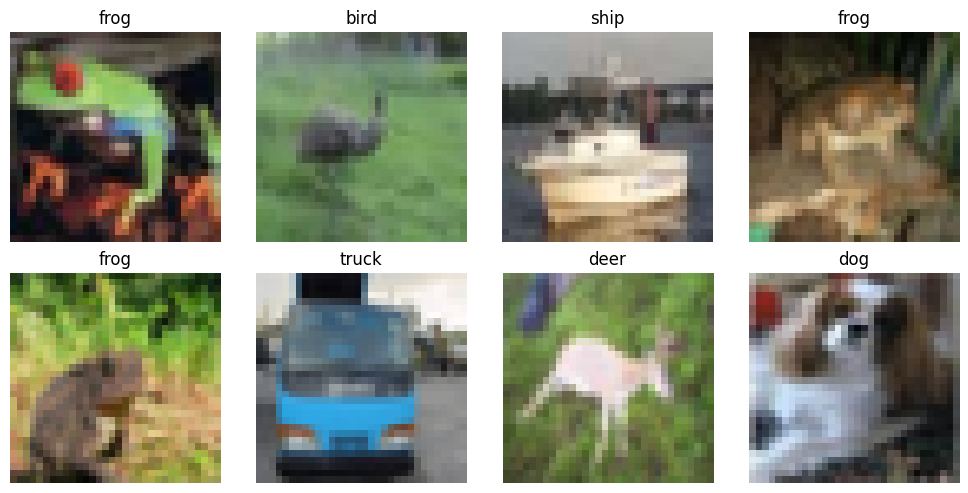

In [4]:
# Выведем 8 изображений с их метками
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
classes = train_dataset_cifar.dataset.classes  # список названий классов

for i, ax in enumerate(axes.flat):
    img, label = train_dataset_cifar[i]
    # Преобразуем тензор в формат из (C, H, W) в (H, W, C) для отображения
    # H - Height, W - Width, C -Channels)
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(classes[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

Теперь создадим `DataLoader`, который будет подавать данные батчами (наборами) во время обучения.  
`DataLoader` перемешивает обучающую выборку (если указать `shuffle=True`) и обеспечивает удобную итерацию по батчам.

Параметр `num_workers=0` означает, что данные загружаются в том же процессе, где выполняется обучение. Это исключает возможные проблемы с многопроцессорностью на некоторых системах (например, Windows). Для небольших датасетов такой подход работает достаточно быстро. При желании значение можно увеличить, чтобы ускорить загрузку, но в нашем случае это не критично.

In [5]:
train_loader_cifar = DataLoader(train_dataset_cifar, batch_size=64, shuffle=True, num_workers=0)
val_loader_cifar = DataLoader(val_dataset_cifar, batch_size=64, shuffle=False, num_workers=0)

Мы подготовили данные. Теперь можно переходить к построению свёрточной нейронной сети.

## Простая CNN для CIFAR-10

Теперь построим свёрточную нейронную сеть (`CNN`) для классификации изображений CIFAR-10.

**Что такое свёртка?**

Свёртка — это операция, при которой небольшой фильтр (ядро) скользит по изображению и вычисляет значение отклика каждой позиции. Фильтр содержит обучаемые веса, которые настраиваются так, чтобы реагировать на определённые паттерны: например, на горизонтальные или вертикальные линии. В начале обучения фильтры дают случайные отклики, но постепенно они "учатся" выделять полезные признаки.

*Пример ниже иллюстрирует свёртку с ядром 3x3 и дополнением границ (на иллюстрации — крайними пикселями; в коде ниже — нулями), чтобы результат свёртки сохранил такое же размер как исходное изображение*

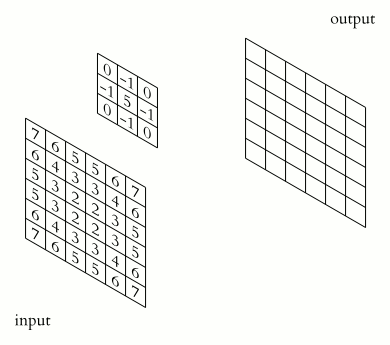

**Зачем нужна функция активации?**

После свёртки часто применяют нелинейную функцию активации, например `ReLU` - она же $f(x) = max(0, x)$. Она заменяет отрицательные значения в карте признаков нулями и оставляет положительные без изменений. Это вносит нелинейность, благодаря которой сеть может аппроксимировать сложные зависимости. Без нелинейности несколько линейных слоёв схлопнулись бы в один линейный. (Линейная функция от линейной функции = Линейная функция)

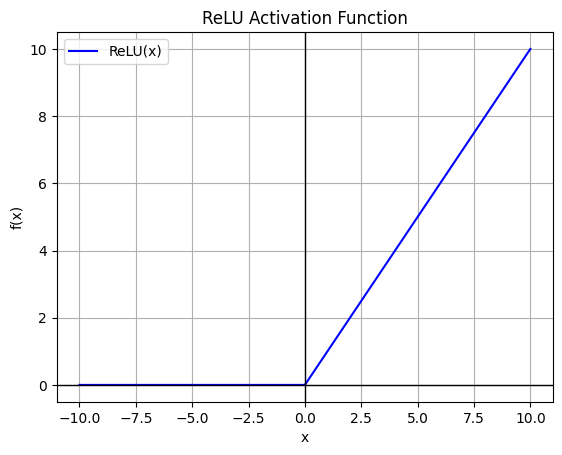

**Что делает пулинг?**

Пулинг (обычно MaxPooling) уменьшает пространственные размеры карты признаков, выбирая максимальное значение в каждом окне. У самого пулинга нет обучаемых весов; меньшая карта уменьшает число параметров следующего полносвязного слоя и вычислительную нагрузку и делает модель более устойчивой к небольшим сдвигам объектов.

*Заметим, что при MaxPooling 2x2 наше изображение 4x4 превратилось в 2x2*

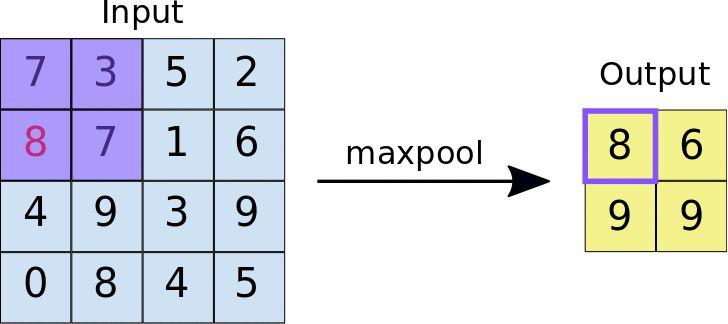

**Что такое `padding`?**

Обычно после свёртки размер карты признаков немного уменьшается: если ядро 3×3, то от каждого края теряется по одному пикселю. Чтобы сохранить исходный размер, можно добавить вокруг изображения рамку из нулей — это называется `padding`. В нашем случае используется padding=1 (один слой нулей вокруг, значения рамки нулевые; `same` описывает сохранение размера, а не значения рамки), поэтому свёртка с ядром 3×3 не меняет пространственные размеры.

*Пример ниже иллюстрирует свёртку с ядром 3x3 и `zero padding`, чтобы результат свёртки сохранил такое же размер как исходное изображение*

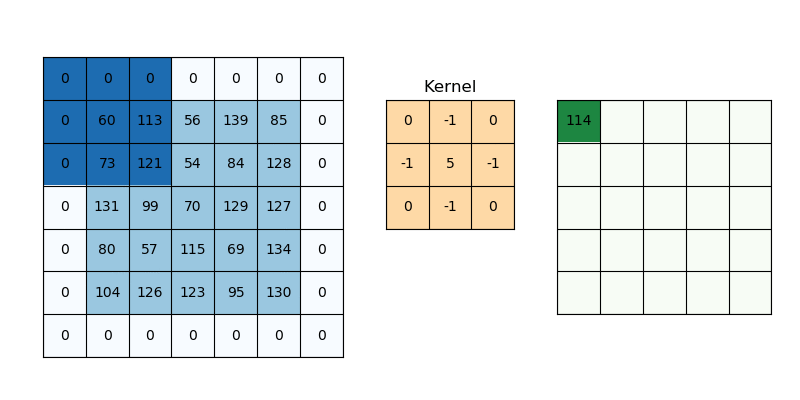

*Здесь то, что происходит в многоканальных изображениях, как RGB - ядро уже имеет фактический размер 3x3x3, в результате работы ядра получается одноканальное изображение, то есть **плоская карта признаков** (1 канал). Применяя N ядер к одному и тому же изображению - получим N каналов, то есть N-канальное изображение*

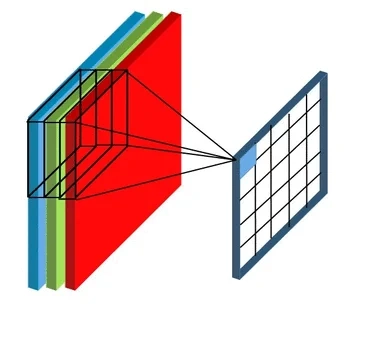

**Как всё сочетается?**

Обычно CNN состоит из блоков: свёртка → активация → пулинг. После нескольких таких блоков пространственный размер становится достаточно маленьким, и мы "вытягиваем" карту признаков в одномерный вектор, который подаём в полносвязные слои для классификации.

Мы реализуем следующую архитектуру:

1. Свёртка 3 → 32 канала, ядро 3×3, padding 1 (сохраняет размер).
2. ReLU, затем MaxPooling 2×2 (уменьшает размер вдвое, 32x32 -> 16x16). **Это пространственные размерности уменьшились! Каналов всё ещё 32!**
4. Свёртка 32 → 64 канала, ядро 3×3, padding 1, ReLU, MaxPooling 2x2. (и снова, 16x16 -> 8x8 из-за MaxPooling 2x2)
5. Свёртка 64 → 128 каналов, ядро 3×3, padding 1, ReLU, MaxPooling 2x2. (и опять, 8x8 -> 4x4 из-за MaxPooling 2x2)
6. Полносвязный слой: 128 * 4 * 4 → 512 → 10.

**Как меняется размер изображения внутри сети?**

На вход подаётся изображение 32×32. После каждого MaxPooling с ядром 2×2 и шагом 2 (как в примере выше) размер уменьшается вдвое. В нашей сети три пулинга, поэтому размеры становятся: 32 → 16 → 8 → 4. После третьего пулинга мы получаем карту признаков 4×4 с 128 каналами. Именно это число (128 * 4 * 4) используется как вход первого полносвязного слоя.

После трёх пулингов изображение 32×32 становится картой признаков 4×4 с 128 каналами. Это и определяет размер входа первого полносвязного слоя.

**А что изменится, если подать изображение 64×64?**

После тех же трёх пулингов размеры будут 64 → 32 → 16 → 8. Теперь перед
полносвязным слоем получится `128 * 8 * 8 = 8192` признака вместо
`128 * 4 * 4 = 2048`. Число входов первого `Linear` нужно изменить соответственно;
иначе размеры тензора и матрицы весов не совпадут. Число весов этого слоя при тех
же 512 выходах вырастет в четыре раза, поэтому увеличение входа обходится дорого.

А число выходов последнего слоя зависит от количества классов, не от размера
картинки: для CIFAR-10 это по-прежнему 10 логитов. Мы оставим вход 32×32 и
создадим класс модели.

In [ ]:
class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.fc_layers = nn.Sequential(
            nn.Linear(128 * 4 * 4, 512),
            nn.ReLU(), # ReLU слой, иначе получим два подряд линейных слоя, в чем нет смысла - их работа моделируется одним линейным слоем
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = x.view(x.size(0), -1)  # вытягиваем изображение в вектор размера 128 x 4 x 4, чтобы подать на вход полносвязному слою
        x = self.fc_layers(x)
        return x

model_cifar = CNN(num_classes=10).to(device)
print(model_cifar)

CNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Linear(in_features=2048, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=10, bias=True)
  )
)


Теперь определим функцию потерь и оптимизатор. Для многоклассовой классификации стандартно используют `CrossEntropyLoss`. Оптимизатор Adam обновляет веса модели, минимизируя эту функцию потерь.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_cifar.parameters(), lr=1e-3)

**Как проходит обучение?**

Обучение нейронной сети состоит из повторяющихся шагов:

1. **Прямой проход (forward):** модель получает батч (набор) изображений и выдаёт предсказания.
2. **Вычисление потерь:** сравниваем предсказания с истинными метками с помощью функции потерь.
3. **Обратный проход (backward):** вычисляются градиенты функции потерь по всем параметрам модели.
4. **Шаг оптимизатора:** веса обновляются в направлении, уменьшающем ошибку предсказания модели.

Эти шаги повторяются для каждого батча. Один полный проход по всем тренировочным данным называется эпохой.

Напишем цикл обучения на 15 эпох. После каждой эпохи будем оценивать модель на validation CIFAR-10 и сохранять историю точности и потерь.

**Функция потерь (CrossEntropyLoss)**

Модель выдаёт на выходе вектор вещественных чисел — **логитов**, по одному числу на каждый класс. Эти числа могут быть любыми: положительными, отрицательными, большими или маленькими. Чтобы интерпретировать их как вероятности, применяют функцию **softmax**:

$$
p_i = \frac{e^{z_i}}{\sum_{j} e^{z_j}},
$$

где $z_i$ — логит для класса $i$, а $p_i$ — получившаяся вероятность. Сумма всех $p_i$ равна 1, то есть мы получаем распределение вероятностей по классам.

Перекрёстная энтропия затем сравнивает это предсказанное распределение с истинным (где у правильного класса вероятность 1, у остальных 0) и вычисляет штраф:

$$
L = -\log(p_{\text{true}}).
$$

Чем меньше вероятность правильного класса, тем больше штраф. Минимизируя эту величину, модель учится увеличивать уверенность в правильном ответе.

В PyTorch `nn.CrossEntropyLoss` устойчиво объединяет log-softmax и вычисление перекрёстной энтропии. Поэтому на вход она принимает именно **логиты**, а не вероятности — не нужно дополнительно применять softmax.

**Пример с числами**

Пусть у нас 3 класса, и модель выдала логиты: $[2.0,\; 1.0,\; 0.1]$.  
Применяем softmax (для простоты округлим):

$$
p = \left[0.659,\; 0.242,\; 0.099\right].
$$

Получили вероятности попадания в каждый из трёх классов.
Если истинный класс — первый, то:

$$
L = -\log(0.659) \approx 0.417.
$$

Если бы модель выдала для правильного класса более высокий логит, например $[5.0, 1.0, 0.1]$, то вероятность стала бы выше, а потеря — меньше. Именно это и происходит в процессе обучения.

**Оптимизатор (Adam)**

Оптимизатор отвечает за обновление весов модели на основе вычисленных градиентов. Adam — один из самых популярных методов: он адаптирует масштаб обновлений разных параметров; базовый learning rate мы задаём сами.

**Важно про выборки train / val / test**

В этом учебном примере (CIFAR-10) мы выделили validation из train. По ней выбираем лучшую эпоху, а встроенную тестовую часть используем один раз после сравнения опытов без аугментаций и с ними.  
В соревновании, с которым связан этот ноутбук, структура немного другая:

- `train` — для обучения модели;
- `val` — для локальной проверки и мониторинга переобучения;
- `test` — выборка, на которой будет оцениваться финальное качество и отправляться посылка в систему контеста.

В самостоятельном решении используйте `val` для оценки во время обучения. Метки `test` соревнования недоступны; этот набор нужен только для итоговых предсказаний.

Для CrossEntropyLoss логиты имеют форму `[B, C]`, а метки — `[B]`, тип `torch.long`, индексы от 0 до C−1. One-hot здесь не нужен.

Теперь напишем цикл обучения на 15 эпох. После каждой эпохи будем оценивать модель на validation CIFAR-10 и сохранять историю точности и потерь.

In [ ]:
epochs = 15
train_loss_history = []
val_acc_history = []
best_acc_cifar = -1.0
best_state_cifar = None
best_epoch_cifar = 0

for epoch in range(epochs):
    # Переключаем модель в режим обучения (важно для Dropout, BatchNorm и т.п.)
    model_cifar.train()
    running_loss = 0.0

    for inputs, labels in train_loader_cifar:
        inputs, labels = inputs.to(device), labels.to(device)

        # Обнуляем градиенты, чтобы они не накапливались от прошлых итераций
        optimizer.zero_grad()

        # Шаг 1. Прямой проход: получаем предсказания модели
        outputs = model_cifar(inputs)

        # Шаг 2. Вычисляем потери между предсказаниями и истинными метками
        loss = criterion(outputs, labels)

        # Шаг 3. Обратный проход: вычисляем градиенты по всем параметрам
        loss.backward()

        # Шаг 4. Обновляем веса с помощью оптимизатора
        optimizer.step()

        # Суммируем потери для отчёта за эпоху
        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_dataset_cifar)
    train_loss_history.append(epoch_loss)

    # Переключаем модель в режим оценки качества
    model_cifar.eval()
    correct = 0
    total = 0
    with torch.no_grad():  # отключаем расчёт градиентов для ускорения вычислений
        for inputs, labels in val_loader_cifar:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_cifar(inputs)
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    val_acc = correct / total
    val_acc_history.append(val_acc)
    if val_acc > best_acc_cifar:
        best_acc_cifar = val_acc
        best_epoch_cifar = epoch + 1
        best_state_cifar = copy.deepcopy(model_cifar.state_dict())

    print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.4f}, Val Acc: {val_acc:.4f}")

model_cifar.load_state_dict(best_state_cifar)

Epoch 1/15, Loss: 1.4866, Val Acc: 0.5624
Epoch 2/15, Loss: 1.0731, Val Acc: 0.6682
Epoch 3/15, Loss: 0.8708, Val Acc: 0.6886
Epoch 4/15, Loss: 0.7445, Val Acc: 0.7096
Epoch 5/15, Loss: 0.6413, Val Acc: 0.7460
Epoch 6/15, Loss: 0.5471, Val Acc: 0.7444
Epoch 7/15, Loss: 0.4617, Val Acc: 0.7484
Epoch 8/15, Loss: 0.3839, Val Acc: 0.7320
Epoch 9/15, Loss: 0.3089, Val Acc: 0.7510
Epoch 10/15, Loss: 0.2429, Val Acc: 0.7394
Epoch 11/15, Loss: 0.1912, Val Acc: 0.7314
Epoch 12/15, Loss: 0.1522, Val Acc: 0.7466
Epoch 13/15, Loss: 0.1164, Val Acc: 0.7366
Epoch 14/15, Loss: 0.1065, Val Acc: 0.7410
Epoch 15/15, Loss: 0.0964, Val Acc: 0.7414


<All keys matched successfully>

**Что происходит в коде?**

- `model.train()` включает режим обучения: активируются слои Dropout и BatchNorm (если есть).
- `model.eval()` переключает модель в режим оценки, отключая Dropout и фиксируя статистики BatchNorm.
- `torch.no_grad()` отключает вычисление градиентов, что ускоряет оценку и экономит память.
- `torch.max(outputs, 1)` возвращает индекс класса с наибольшим значением (предсказанный класс).

Построим графики, чтобы наглядно увидеть, как менялись потери и точность по эпохам.

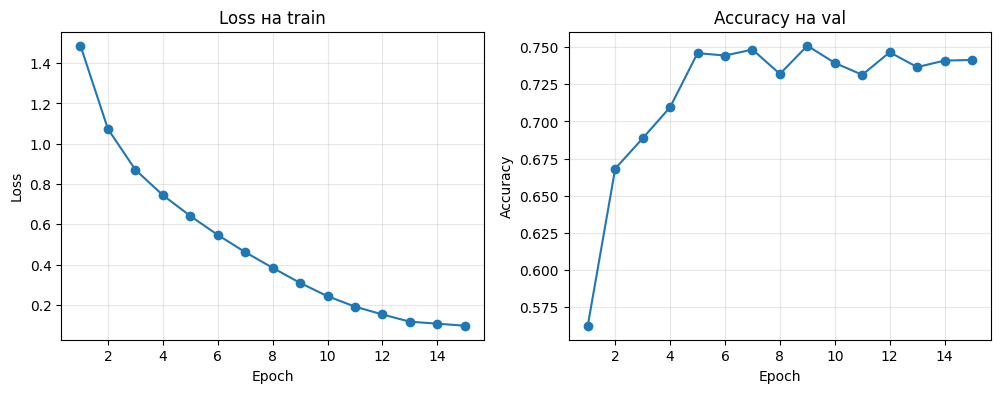

In [ ]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), train_loss_history, marker='o')
plt.title('Loss на train')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), val_acc_history, marker='o')
plt.title('Accuracy на val')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True, alpha=0.3)

plt.show()

## Аугментации данных

До сих пор мы обучали модель на исходных изображениях, только переводя их в тензоры. Теперь проверим, поможет ли искусственное расширение обучающей выборки.

**Что такое аугментации?**

Аугментации — это случайные преобразования тренировочных изображений, которые не меняют их смысл (класс), но делают данные более разнообразными. Например, изображение можно немного повернуть, отразить по горизонтали, изменить яркость или контраст. Благодаря этому модель видит больше вариантов одного и того же объекта и меньше переобучается к конкретным деталям тренировочных снимков.

Важно: аугментации применяются **только к обучающей выборке**. Валидационную и тестовую выборки мы не искажаем, чтобы оценка оставалась объективной.

**Какие аугментации мы будем использовать?**

- `RandomHorizontalFlip` — случайное отражение по горизонтали.
- `RandomRotation(10)` — поворот на случайный угол до 10 градусов.
- `ColorJitter(brightness=0.2, contrast=0.2)` — небольшое изменение яркости и контраста.

Для CIFAR-10 небольшие повороты, отражения и изменения яркости обычно сохраняют класс объекта. Однако полезность этих преобразований нужно проверить по validation. Для другого датасета допустимые преобразования придётся выбирать заново.

Посмотрим, как выглядят аугментации на примере одного изображения.

Для наглядной демонстрации аугментаций возьмём одно исходное изображение из обучающей выборки.  
В PyTorch аугментации из `torchvision.transforms` обычно применяются к изображениям в формате `PIL (Python Imaging Library)`. Поэтому мы переведём тензор обратно в PIL с помощью `ToPILImage`, а затем применим к нему те же преобразования, которые будут использоваться при обучении. Это позволит увидеть, как меняется изображение при каждом случайном преобразовании.

`CIFAR10` также передаёт PIL-изображение в трансформации перед преобразованием в тензор.

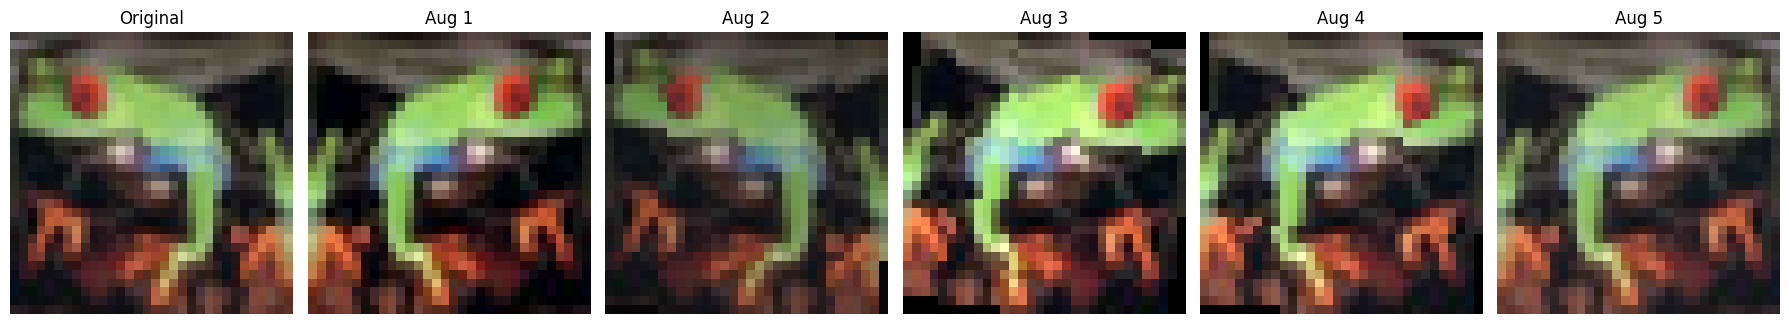

In [10]:
# Возьмём одно изображение из train CIFAR-10
img_tensor, _ = train_dataset_cifar[0]
img_pil = transforms.ToPILImage()(img_tensor)

# Преобразование для визуализации аугментаций (без нормализации, только ToTensor, приводим к [0, 1])
aug_transform_vis = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
])

fig, axes = plt.subplots(1, 6, figsize=(18, 4))
axes[0].imshow(img_pil)
axes[0].set_title("Original")
axes[0].axis('off')

for i in range(1, 6):
    aug_img = aug_transform_vis(img_pil)
    axes[i].imshow(aug_img.permute(1, 2, 0).numpy())
    axes[i].set_title(f"Aug {i}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

Как видно, каждое преобразование даёт немного другое изображение, но сохраняется ли полезная информация, нужно проверять.

Теперь добавим аугментации в `train_transform` и обучим модель заново. Валидационный набор оставим без изменений, чтобы честно сравнивать качество.

In [11]:
train_transform_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
])

# Отдельный экземпляр CIFAR-10: трансформации validation не изменяются.
cifar_aug = datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform_aug)
# Берём те же 45000 индексов train, что и в первом опыте.
train_dataset_aug = Subset(cifar_aug, train_dataset_cifar.indices)
train_loader_aug = DataLoader(train_dataset_aug, batch_size=64, shuffle=True, num_workers=0)

Создадим новую модель той же архитектуры, чтобы обучение с аугментациями началось с того же стартового состояния (с фиксированным seed это будет та же инициализация).

In [12]:
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
model_aug = CNN(num_classes=10).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_aug = optim.Adam(model_aug.parameters(), lr=1e-3)

Запускаем цикл обучения

In [13]:
epochs = 15
train_loss_aug = []
val_acc_aug = []
best_acc_aug = -1.0
best_epoch_aug = 0
best_state_aug = None

for epoch in range(epochs):
    model_aug.train()
    running_loss = 0.0
    for inputs, labels in train_loader_aug:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_aug.zero_grad()
        outputs = model_aug(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_aug.step()
        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_dataset_aug)
    train_loss_aug.append(epoch_loss)

    model_aug.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in val_loader_cifar:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_aug(inputs)
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    val_acc = correct / total
    val_acc_aug.append(val_acc)
    if val_acc > best_acc_aug:
        best_acc_aug = val_acc
        best_epoch_aug = epoch + 1
        best_state_aug = copy.deepcopy(model_aug.state_dict())
    print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.4f}, Val Acc: {val_acc:.4f}")

model_aug.load_state_dict(best_state_aug)

Epoch 1/15, Loss: 1.5456, Val Acc: 0.5640
Epoch 2/15, Loss: 1.1495, Val Acc: 0.6274
Epoch 3/15, Loss: 0.9762, Val Acc: 0.6986
Epoch 4/15, Loss: 0.8656, Val Acc: 0.7166
Epoch 5/15, Loss: 0.7972, Val Acc: 0.7034
Epoch 6/15, Loss: 0.7336, Val Acc: 0.7454
Epoch 7/15, Loss: 0.6829, Val Acc: 0.7542
Epoch 8/15, Loss: 0.6445, Val Acc: 0.7660
Epoch 9/15, Loss: 0.6025, Val Acc: 0.7426
Epoch 10/15, Loss: 0.5751, Val Acc: 0.7722
Epoch 11/15, Loss: 0.5443, Val Acc: 0.7632
Epoch 12/15, Loss: 0.5152, Val Acc: 0.7834
Epoch 13/15, Loss: 0.4942, Val Acc: 0.7846
Epoch 14/15, Loss: 0.4663, Val Acc: 0.7690
Epoch 15/15, Loss: 0.4389, Val Acc: 0.7856


<All keys matched successfully>

И наконец, визуализируем, чтобы наглядно увидеть, как менялись потери и точность по эпохам - сравним подходы без аугментации и с аугментацией.

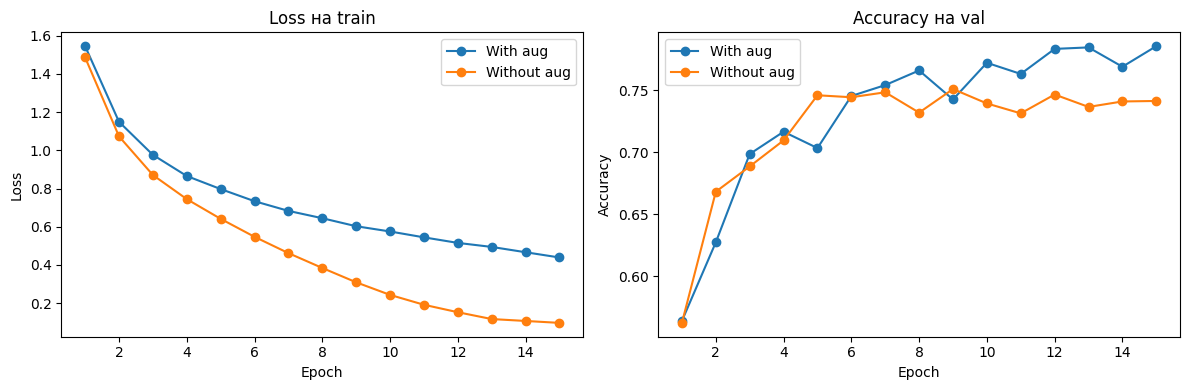

In [14]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), train_loss_aug, marker='o', label='With aug')
plt.plot(range(1, epochs+1), train_loss_history, marker='o', label='Without aug')
plt.title('Loss на train')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), val_acc_aug, marker='o', label='With aug')
plt.plot(range(1, epochs+1), val_acc_history, marker='o', label='Without aug')
plt.title('Accuracy на val')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
results = pd.DataFrame({
    'experiment': ['without_aug', 'with_aug'],
    'best_epoch': [best_epoch_cifar, best_epoch_aug],
    'val_accuracy': [best_acc_cifar, best_acc_aug],
    'last_val_accuracy': [val_acc_history[-1], val_acc_aug[-1]],
})
print(results.to_string(index=False))

 experiment  best_epoch  val_accuracy  last_val_accuracy
without_aug           9        0.7510             0.7414
   with_aug          15        0.7856             0.7856


**Что мы видим?**

Начнём с левого графика: как меняется loss на train? Если она снижается, модель
учится лучше отвечать на обучающих примерах. Но достаточно ли этого, чтобы
выбрать лучшую модель? Посмотрим на правый график — accuracy на validation.

**В какую эпоху качество было лучшим?**

В таблице `best_epoch` — номер лучшей эпохи, `val_accuracy` — её точность,
а `last_val_accuracy` — точность после последней эпохи. Если loss продолжает
снижаться, а val accuracy уже падает, это признак переобучения: запоминание
train не даёт такого же улучшения на новых изображениях. Поэтому мы сохраняли
лучшие веса, а не просто брали последнюю модель.

**Что изменили аугментации?**

Сравните два опыта при одинаковом числе эпох. С аугментациями модель видит
более разнообразные и иногда более сложные изображения, поэтому train loss
может быть выше. Это само по себе не означает, что модель хуже: loss теперь
считается на изменённых картинках. Для сравнения у нас есть одна и та же validation
без случайных преобразований. Стал ли выше максимум accuracy? Позже ли он
достигнут? Что происходит к последней эпохе?

**Пример разбора полного запуска**

В проверочном запуске на CPU с seed=42 и 15 эпохами без аугментаций лучшая
val accuracy была 0.7544 на эпохе 9,
а после последней эпохи — 0.7404.
С аугментациями максимум составил 0.7848 на эпохе
15, после последней эпохи — 0.7848.
По нашему правилу выбираем лучшие веса модели с аугментациями.

В этом опыте аугментации повысили лучшую val accuracy на 3.04
процентного пункта. Более высокая loss на изменённых train-картинках сама по себе
не мешает получить лучшее качество на неизменной validation.

Обратите внимание на опыт без аугментаций: после лучшей эпохи train loss
снизилась с 0.3149
до 0.0921 к концу обучения,
но val accuracy стала ниже максимума.
Это как раз тот случай, когда меньшая ошибка на train не означает лучшего
обобщения. Сохранение лучших весов здесь влияет на то, какую модель мы получим.

Это результат одного запуска, а не обещание таких же чисел в другом окружении.
Сверьте этот разбор со своими кривыми и таблицей: если они отличаются,
вывод о выборе модели делайте по своим результатам.

Для учебного CSV выберем лучшую val accuracy среди обоих опытов и всех их эпох.
При равенстве оставим опыт без аугментаций. Теперь перейдём к сохранению модели
и созданию файла с предсказаниями для тестовой выборки.

## Сохранение модели и файла с предсказаниями

Для участия в соревновании нужно сформировать CSV-файл с предсказаниями для тестовой
выборки. Покажем этот шаг на CIFAR-10. Формат нашего **учебного** файла:

- `id` — идентификатор изображения, например `cifar10_00000`;
- `label` — предсказанный класс CIFAR-10 (целое число от 0 до 9).

В CIFAR-10 готовые ID не заданы, поэтому будем использовать индекс изображения
в официальной тестовой части. Файл назовём `cifar10_predictions.csv`:
его нельзя отправлять в контест, где другие изображения, ID и классы.

**План действий:**

1. Выбрать модель по лучшей val accuracy из двух опытов и сохранить её лучшие веса.
2. Загрузить эти веса и тестовые изображения с теми же преобразованиями, что и для validation.
3. Сделать предсказания, сохраняя ID рядом с каждым ответом.
4. Сформировать DataFrame с колонками `id` и `label`, проверить и сохранить в CSV.

Не выбираем модель по test. Сохраним веса и настройки преобразований вместе,
чтобы повторить предсказания после перезапуска. При равной val accuracy оставим
опыт без аугментаций.

**Зачем нужен собственный класс Dataset?**

Обычный `CIFAR10` возвращает пару «изображение, метка». Для создания CSV нам
нужна пара «изображение, ID». Напишем простой `TestDataset`, который наследуется
от `torch.utils.data.Dataset` и оборачивает тестовую часть CIFAR-10. Он будет:

- хранить исходный датасет и список ID;
- по индексу брать изображение, игнорируя метку;
- возвращать изображение и его ID.

Этот класс позволит нам итерироваться по тестовой выборке с помощью `DataLoader`
и одновременно сохранять ID, чтобы правильно сформировать файл с предсказаниями.
Как перейти к изображениям в обычных файлах, разберём в советах
по работе с данными соревнования в конце ноутбука.

In [16]:
selected_model = model_aug if best_acc_aug > best_acc_cifar else model_cifar
checkpoint = {
    'state_dict': selected_model.state_dict(),
    'num_classes': 10,
    'image_size': 32,
    'transform': 'ToTensor',
    'classes': classes,
    'seed': seed,
    'best_epoch': best_epoch_aug if best_acc_aug > best_acc_cifar else best_epoch_cifar,
    'val_accuracy': max(best_acc_cifar, best_acc_aug),
}
torch.save(checkpoint, 'selected_cifar10.pt')
checkpoint = torch.load('selected_cifar10.pt', map_location=device, weights_only=True)
selected_model = CNN(num_classes=checkpoint['num_classes']).to(device)
selected_model.load_state_dict(checkpoint['state_dict'])

<All keys matched successfully>

In [17]:
class TestDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset
        self.ids = [f'cifar10_{index:05d}' for index in range(len(dataset))]

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, _ = self.dataset[index]  # Метка не участвует в предсказании.
        return image, self.ids[index]

Преобразования для тестовой выборки должны быть такими же, как для validation.
В нашем примере это только `ToTensor`: размер изображений уже 32×32, нормализацию
мы не добавляли. Аугментации при итоговой оценке не применяем.

Создадим DataLoader с изображениями и ID. Метки CIFAR-10 понадобятся только
после получения CSV, чтобы один раз оценить итоговое качество выбранной модели.
В тестовой части соревнования меток у вас не будет.

In [18]:
assert checkpoint['image_size'] == 32 and checkpoint['transform'] == 'ToTensor'
test_dataset_cifar.transform = transforms.ToTensor()
test_dataset = TestDataset(test_dataset_cifar)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)

print(f"Test size: {len(test_dataset)}")

Test size: 10000


Из цикла обучения берём только часть с оценкой, чтобы получить предсказания

In [19]:
# Переводим модель в режим оценки
selected_model.eval()

test_ids = []
test_preds = []

with torch.no_grad():
    for inputs, ids in test_loader:
        inputs = inputs.to(device)
        outputs = selected_model(inputs)
        _, preds = torch.max(outputs, 1)
        test_preds.extend(preds.cpu().numpy())
        # ID сохраняем из того же батча, что и предсказания
        test_ids.extend(ids)

In [20]:
# Создаём DataFrame и проверяем формат учебного CSV
submission = pd.DataFrame({'id': test_ids, 'label': test_preds})
assert submission['id'].is_unique and set(submission['id']) == set(test_dataset.ids)
assert len(submission) == len(test_dataset) == 10000
assert submission['label'].between(0, 9).all()
assert pd.api.types.is_integer_dtype(submission['label'])
submission = submission.set_index('id').loc[test_dataset.ids].reset_index()
submission.to_csv('cifar10_predictions.csv', index=False)
print("Файл cifar10_predictions.csv сохранён")
print(submission.head())

# Итоговая оценка CIFAR-10 после выбора модели по validation
test_labels = pd.Series(test_dataset_cifar.targets, index=test_dataset.ids)
correct = submission['label'].to_numpy() == test_labels.loc[submission['id']].to_numpy()
print(f"CIFAR-10: итоговая test accuracy = {correct.mean():.4f}")

Файл cifar10_predictions.csv сохранён
              id  label
0  cifar10_00000      3
1  cifar10_00001      8
2  cifar10_00002      0
3  cifar10_00003      0
4  cifar10_00004      6
CIFAR-10: итоговая test accuracy = 0.7836


Мы рассмотрели полный цикл решения на CIFAR-10: от загрузки данных и построения
CNN до сохранения модели и получения файла с предсказаниями.

## Теперь ваша очередь: данные соревнования

В соревновании нужно самостоятельно построить такой же рабочий процесс для
других изображений. В выданном наборе `mri_classification_dataset`:

- `train/class_0` … `train/class_4` — 1390 обучающих изображений;
- `val/class_0` … `val/class_4` — 298 изображений для выбора модели;
- `test` — 300 изображений без доступных меток;
- `sample_submission.csv` — образец CSV с колонками `id,label`. Нули в нём — заглушки.

**Что предстоит сделать самостоятельно?**

1. Посмотреть изображения и размеры, проверить соответствие `class_0` → 0, …,
   `class_4` → 4. Для размеченных папок подойдёт `torchvision.datasets.ImageFolder`:
   его работу разберём ниже на десяти учебных картинках. Для `test` напишите свой Dataset,
   который открывает изображение и возвращает его вместе с ID.
2. Выбрать размер входа и преобразования. Изображения контеста имеют размер
   256×256 или 512×512; при изменении входного размера пересчитайте размер
   карты признаков перед `Linear`. Сколько выходов должно быть у вашей CNN?
3. Обучить CNN с нуля, выбирая лучшую эпоху по val accuracy. Проверить отдельным
   опытом, помогают ли выбранные аугментации, и объяснить результат по графикам.
4. Сохранить выбранную модель вместе с преобразованиями и соответствием классов.
   После загрузки весов получить предсказания для всех test-изображений.
5. Создать `submission.csv`: `id` — имя test-файла без расширения, `label` —
   целое число от 0 до 4. Проверить, что все ID из `sample_submission.csv`
   встречаются ровно один раз; порядок строк не важен. Подготовить исполняемый
   notebook с описанием своих экспериментов.

В решении контеста разрешены только выданные данные и обучение CNN с нуля. Не переносите в решение веса, обученные на CIFAR-10.
Предобученные веса, ручная разметка test и обмен ответами запрещены.
Порог accuracy ≥ 0.85 — цель самостоятельной работы;
качество на CIFAR-10 не говорит о прохождении этого порога.

Ниже разберём работу с файлами и идеи для отдельных экспериментов.

## Советы по работе с данными соревнования

В контесте изображения лежат в обычных папках и имеют разные размеры.
Разберём нужные приёмы на нескольких уже знакомых картинках CIFAR-10.

**А если изображения лежат в обычных файлах?**

`CIFAR10` уже знает, как устроен учебный набор, и сам загружает изображения и метки.
Но часто данные выдают просто в папках. Как работать с ними?

Для загрузки данных из папок с подпапками по классам удобно использовать
`torchvision.datasets.ImageFolder`. Он автоматически присвоит метки классам
в алфавитном порядке папок. Соответствие можно посмотреть в `class_to_idx`.

Посмотрим на маленьком примере. Сохраним по одному изображению из каждого класса
**обучающей части** CIFAR-10 в PNG-файлы: например,
`cifar10_examples/airplane/airplane.png` и `cifar10_examples/frog/frog.png`.
`ImageFolder` определит класс по подпапке, а не по имени самого файла.
Затем загрузим эти же изображения с помощью `ImageFolder`.

Это десять картинок для знакомства с загрузкой из файлов. В опытах выше
мы обучались на всех 45000 изображениях `train_dataset_cifar`.

**А как написать свой Dataset для test?**

В примере ниже откроем картинку через `Image.open`, приведём её к RGB
и получим ID через `Path.stem`.
В файловом Dataset эти действия выполняются в `__getitem__`: берём путь по
индексу, открываем изображение, применяем преобразования и возвращаем тензор
вместе с ID. Список путей удобно один раз собрать в `__init__`.
`ImageFolder` для папки без подпапок классов не подойдёт — именно такой
загрузчик вам предстоит написать для test соревнования.

In [21]:
# Создадим маленький файловый пример из уже загруженного train CIFAR-10.
demo_dir = Path('cifar10_examples')
for label, class_name in enumerate(classes):
    index = next(i for i in train_dataset_cifar.indices
                 if train_dataset_cifar.dataset.targets[i] == label)
    image_tensor, _ = train_dataset_cifar.dataset[index]
    class_dir = demo_dir / class_name
    class_dir.mkdir(parents=True, exist_ok=True)
    transforms.ToPILImage()(image_tensor).save(class_dir / f'{class_name}.png')

file_dataset = datasets.ImageFolder(demo_dir, transform=transforms.ToTensor())
print('Соответствие классов:', file_dataset.class_to_idx)

# Отдельное изображение можно открыть и без ImageFolder.
example_path = Path(file_dataset.samples[0][0])
with Image.open(example_path) as image:
    example_image = image.convert('RGB')
file_tensor = transforms.ToTensor()(example_image)
print('ID из имени файла:', example_path.stem)
print('Размер тензора:', file_tensor.shape)

Соответствие классов: {'airplane': 0, 'automobile': 1, 'bird': 2, 'cat': 3, 'deer': 4, 'dog': 5, 'frog': 6, 'horse': 7, 'ship': 8, 'truck': 9}
ID из имени файла: airplane
Размер тензора: torch.Size([3, 32, 32])


**Зачем изменять размер изображения?**

В CIFAR-10 все изображения уже имеют размер 32×32. В другом наборе размеры могут
различаться, а для обычного батча нам нужны тензоры одинаковой формы.
`transforms.Resize((height, width))` приводит их к выбранному размеру.
Больший вход требует больше вычислений; уменьшение изображения может потерять
мелкие детали. Размер входа — одно из решений, которые нужно проверять на validation.

**Что делает нормализация?**

После `ToTensor()` значения пикселей находятся в диапазоне [0, 1].
`Normalize(mean, std)` отдельно для каждого цветового канала вычисляет
`normalized = (original - mean) / std`. Три числа в `mean` и `std`
соответствуют каналам RGB.

Для наглядности возьмём `mean = std = [0.5, 0.5, 0.5]`: тогда значения [0, 1]
перейдут в [-1, 1]. Это выбранные для примера числа, а не вычисленные статистики
CIFAR-10; они не делают среднее нашего набора равным нулю, а дисперсию — единице.
Если решите оценить среднее и стандартное отклонение по данным, используйте только
train и затем применяйте те же значения к validation и test.

**Как показать нормализованное изображение?**

Перед визуализацией выполняем обратное преобразование:
`original = normalized * std + mean`. С помощью `view(3, 1, 1)` превращаем
три числа для RGB в тензор, который можно применять к изображению формы `(3, H, W)`.
После этого `permute(1, 2, 0)` меняет порядок осей на `(H, W, C)` для matplotlib.

Покажем оба преобразования на сохранённой картинке. Размер 64×64 здесь выбран
только для демонстрации: увеличение не восстанавливает детали исходного CIFAR-10.
В двух опытах обучения выше мы использовали 32×32 и `ToTensor()`. Добавление
нормализации можно проверить отдельным экспериментом.

Размер после Resize: torch.Size([3, 64, 64])
Диапазон после Normalize: [-0.96, 0.93]


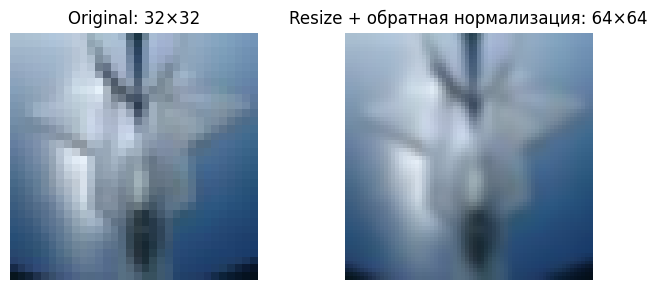

In [22]:
demo_mean = [0.5, 0.5, 0.5]
demo_std = [0.5, 0.5, 0.5]
demo_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(demo_mean, demo_std),
])
normalized = demo_transform(example_image)
restored = (normalized * torch.tensor(demo_std).view(3, 1, 1)
            + torch.tensor(demo_mean).view(3, 1, 1))
print('Размер после Resize:', normalized.shape)
print(f'Диапазон после Normalize: [{normalized.min():.2f}, {normalized.max():.2f}]')

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(example_image)
axes[0].set_title('Original: 32×32')
axes[1].imshow(restored.permute(1, 2, 0).numpy())
axes[1].set_title('Resize + обратная нормализация: 64×64')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Идеи для улучшения

Наш учебный пример — это простая CNN для CIFAR-10, обученная с нуля. Его можно улучшить разными способами. Ниже перечислены направления для отдельных экспериментов. Выбирайте изменения по validation, не по частым проверкам test. Для самостоятельного решения соблюдайте ограничения соревнования, перечисленные выше.

### 1. Аугментации данных

**Идея.**  
Мы использовали минимальный набор аугментаций: случайное отражение, небольшой поворот, лёгкое изменение яркости и контраста. Можно попробовать более разнообразные преобразования, чтобы модель стала ещё устойчивее.

**Что можно добавить:**

- Случайное кадрирование с последующим масштабированием (`RandomResizedCrop`) — делает модель инвариантнее к положению объекта.
- Увеличить диапазон поворота, например, до 20 градусов.
- Добавить случайное вертикальное отражение (но для медицинских изображений это может быть нежелательно, поэтому проверяйте).
- Использовать более сильные изменения яркости, контраста, насыщенности.
- Попробовать продвинутые методы, такие как MixUp или CutMix (реализованы в библиотеке `timm`).

---

### 2. Test-Time Augmentation (TTA)

**Идея.**  
Обычно аугментации применяются только при обучении. Но можно использовать их и на этапе предсказания. Для каждого тестового изображения мы делаем несколько его случайных преобразований, получаем предсказания для каждого варианта и усредняем вероятности. Это уменьшает случайную ошибку и часто повышает точность.

**Как это сделать.**  
Нужно изменить цикл предсказания: для каждого батча тестовых изображений генерировать несколько аугментированных копий (например, 5), прогонять их через модель, собирать вероятности, усреднять и затем выбирать класс.

---

### 3. Ансамблирование

**Идея.**  
Ансамблирование — это комбинирование предсказаний нескольких моделей. Один из простых и эффективных способов — обучить несколько моделей с разными случайными seed и усреднить их предсказания.

**Почему разные seed дают разные модели?**  
Seed влияет на начальную инициализацию весов, порядок перемешивания данных и случайные аугментации. Поэтому модели получаются разными и могут ошибаться по-разному. Усреднение их ответов сглаживает ошибки и часто улучшает результат.

**Как это сделать практически.**  
Обучите модель несколько раз, меняя seed перед фиксацией (например, 42, 666, 1337). Для каждой модели получите предсказания на тесте. Затем усредните вероятности и выберите класс с наибольшим средним значением. Перед усреднением вероятностей примените softmax к логитам. Усреднение логитов даёт другой ансамбль; какой способ лучше, проверяют на validation.

---

### 4. Настройка гиперпараметров

**Идея.**  
Гиперпараметры — это параметры, которые не обучаются автоматически, а задаются вручную: learning rate, batch size, количество эпох, dropout, тип оптимизатора. Их подбор может заметно улучшить качество.

**Что можно менять:**

- **learning rate** — например, попробовать 1e-3, 5e-4, 1e-4. Слишком большой lr приводит к нестабильному обучению, слишком маленький — к медленной сходимости.
- **batch size** — 16, 32, 64. Влияет на шум градиента и использование памяти.
- **количество эпох** — иногда модель продолжает улучшаться после 15 эпох, но возможен и переобучающий эффект.
- **dropout** — добавить слой Dropout и подобрать его вероятность; в нашей CIFAR CNN его пока нет.
- **оптимизатор** — попробовать AdamW или SGD с моментом.

**Планировщик learning rate.**  
Полезный инструмент — автоматическое уменьшение learning rate в процессе обучения. В PyTorch есть готовые планировщики: `CosineAnnealingLR`, `ReduceLROnPlateau` и др. Они помогают точнее сойтись к минимуму.

**Как это сделать.**  
Измените соответствующие параметры в коде, добавьте планировщик перед циклом обучения и вызывайте его шаг после каждой эпохи (или после оценки на валидации).

**Ожидаемый эффект.**  
Зависит от данных и настроек; прирост проверяется экспериментом, а не гарантируется.

---

### 5. Псевдо-лейблинг

**Идея.**  
Псевдо-лейблинг — это метод, при котором мы используем предсказания модели на неразмеченных данных (в нашем случае — на тестовой выборке) как дополнительные обучающие примеры с «псевдо-метками».

**Как это работает.**  
Сначала обучаем модель на размеченных данных (`train`). Затем делаем предсказания для тестовых изображений и отбираем те, в которых модель уверена больше всего (например, вероятность правильного класса выше 0.95). Добавляем эти изображения с их предсказанными метками в обучающую выборку и обучаем модель заново.

**На что обратить внимание.**  
- Порог уверенности нужно подбирать: слишком низкий добавит много ошибочных меток, слишком высокий — мало новых данных.
- Псевдо-лейблинг может как улучшить, так и ухудшить результат. Если модель ошибается в уверенных предсказаниях, ошибки закрепятся.
- В условиях соревнования, где тестовая выборка используется для оценки, этот метод может привести к переобучению под конкретный тест. Поэтому использовать его нужно осторожно и скорее в учебных целях.

# Заключение

Вы прошли весь путь от загрузки данных до файла с предсказаниями на CIFAR-10. Теперь примените эти шаги к данным соревнования самостоятельно. Желаем успехов в соревновании!

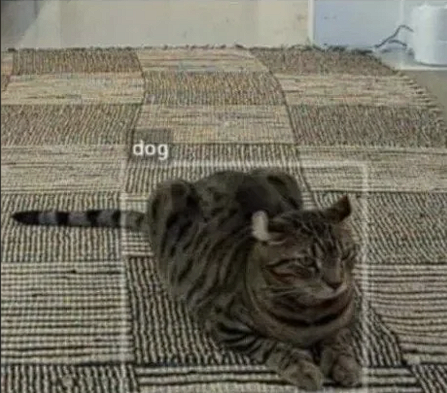